# Homework 3: Performance Analysis of Nvidia Rapids for data analysis

## Setup

### GPU Specs
*Using 1 V100 GPU with 32GB VRAM*

In [3]:
!nvidia-smi

Tue Oct 20 16:46:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla V100-PCIE-32GB           On  |   00000000:D8:00.0 Off |                    0 |
| N/A   26C    P0             25W /  250W |       0MiB /  32768MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### CPU Specs

*Using a 32 core cpu*

In [4]:
!lscpu

Architecture:        x86_64
CPU op-mode(s):      32-bit, 64-bit
Byte Order:          Little Endian
CPU(s):              32
On-line CPU(s) list: 0-31
Thread(s) per core:  1
Core(s) per socket:  16
Socket(s):           2
NUMA node(s):        2
Vendor ID:           GenuineIntel
CPU family:          6
Model:               85
Model name:          Intel(R) Xeon(R) Gold 6130 CPU @ 2.10GHz
Stepping:            4
CPU MHz:             2100.000
BogoMIPS:            4200.00
Virtualization:      VT-x
L1d cache:           32K
L1i cache:           32K
L2 cache:            1024K
L3 cache:            22528K
NUMA node0 CPU(s):   0,2,4,6,8,10,12,14,16,18,20,22,24,26,28,30
NUMA node1 CPU(s):   1,3,5,7,9,11,13,15,17,19,21,23,25,27,29,31
Flags:               fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush dts acpi mmx fxsr sse sse2 ss ht tm pbe syscall nx pdpe1gb rdtscp lm constant_tsc art arch_perfmon pebs bts rep_good nopl xtopology nonstop_tsc cpuid aperfmperf pni pclmulqd

### Memory Specs

*With 175GB available*

In [5]:
!free -h

              total        used        free      shared  buff/cache   available
Mem:          187Gi       2.9Gi        42Gi       7.7Gi       142Gi       175Gi
Swap:            0B          0B          0B


## Test

In [ ]:
import numpy as np
import pandas as pd
import cudf as cf
import cupy as cp
from matplotlib import pyplot as plt

### Run with `nrows=10`

In [ ]:
nrows = 10

df1_data = {
'key': np.random.choice(['A', 'B', 'C', 'D'], size=nrows),
'value1': np.random.randint(1, 101, size=nrows)
}
df1 = pd.DataFrame(df1_data)


df2_data = {
'key': np.random.choice(['D', 'B', 'E', 'F'], size=nrows),
'value2': np.random.randint(1, 101, size=nrows)
}

df2 = pd.DataFrame(df2_data)

gpu_df1 = cf.from_pandas(df1)
gpu_df2 = cf.from_pandas(df2)

#### Verify the output

In [ ]:
print("Testing merge operation:")
result = df1.merge(df2, on='key', how='inner')
gpu_result = gpu_df1.merge(gpu_df2, on='key', how='inner')
print(f"CPU\n{result.head()}\nGPU\n{gpu_result.head()}")

print("\nTesting group operation:")
result = df1.groupby('key').size()
gpu_result = gpu_df1.groupby('key').size()
print(f"CPU\n{result}\nGPU\n{gpu_result}")

print("\nTesting sort operation:")
result = df1.sort_values(by='value1')
gpu_result = gpu_df1.sort_values(by='value1')
print(f"CPU\n{result.head()}\nGPU\n{gpu_result.head()}")

### Run with `nrows=5000`

*Note on methods of timing:*
* For GPU operation, device synchrinization is applied after each run via `cp.cuda.Device().synchronize()` to ensure that GPU has actually finished its work when the timer stops.
* For both devices, one untimed run is performed to avoid first time overhead such as JIT compilation or caching, allow the runtime to be representitive.

In [21]:
nrows = 5000

df1_data = {
'key': np.random.choice(['A', 'B', 'C', 'D'], size=nrows),
'value1': np.random.randint(1, 101, size=nrows)
}
df1 = pd.DataFrame(df1_data)


df2_data = {
'key': np.random.choice(['D', 'B', 'E', 'F'], size=nrows),
'value2': np.random.randint(1, 101, size=nrows)
}

df2 = pd.DataFrame(df2_data)

gpu_df1 = cf.from_pandas(df1)
gpu_df2 = cf.from_pandas(df2)

In [22]:
print("Testing merge operation:")
print("\tOn CPU")
result = df1.merge(df2, on='key', how='inner')
%timeit -n 5 result = df1.merge(df2, on='key', how='inner')
print("\n\tOn GPU")
gpu_result = gpu_df1.merge(gpu_df2, on='key', how='inner')
%timeit -n 5 gpu_result = gpu_df1.merge(gpu_df2, on='key', how='inner'); cp.cuda.Device().synchronize()

print("\nTesting group operation:")
print("\tOn CPU")
result = df1.groupby('key').size()
%timeit -n 5 result = df1.groupby('key').size()
print("\n\tOn GPU")
result = gpu_df1.groupby('key').size()
%timeit -n 5 result = gpu_df1.groupby('key').size(); cp.cuda.Device().synchronize()

print("\nTesting sort operation:")
print("\tOn CPU")
result = df1.sort_values(by='value1')
%timeit -n 5 result = df1.sort_values(by='value1')
print("\n\tOn GPU")
result = gpu_df1.sort_values(by='value1')
%timeit -n 5 result = gpu_df1.sort_values(by='value1'); cp.cuda.Device().synchronize()

Testing merge operation:
	On CPU
97.7 ms ± 872 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)

	On GPU
15.9 ms ± 781 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)

Testing group operation:
	On CPU
519 μs ± 34.2 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)

	On GPU
1.25 ms ± 22.1 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)

Testing sort operation:
	On CPU
363 μs ± 16.2 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)

	On GPU
1.53 ms ± 233 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)


### Run with `nrows=50000`
*merge operation on cpu only run once as it took too long time*

In [27]:
nrows = 50000

df1_data = {
'key': np.random.choice(['A', 'B', 'C', 'D'], size=nrows),
'value1': np.random.randint(1, 101, size=nrows)
}
df1 = pd.DataFrame(df1_data)


df2_data = {
'key': np.random.choice(['D', 'B', 'E', 'F'], size=nrows),
'value2': np.random.randint(1, 101, size=nrows)
}

df2 = pd.DataFrame(df2_data)

gpu_df1 = cf.from_pandas(df1)
gpu_df2 = cf.from_pandas(df2)

In [28]:
print("Testing merge operation:")
print("\tOn CPU")
result = df1.merge(df2, on='key', how='inner')
%timeit -n 1 result = df1.merge(df2, on='key', how='inner')
print("\n\tOn GPU")
gpu_result = gpu_df1.merge(gpu_df2, on='key', how='inner')
%timeit -n 5 gpu_result = gpu_df1.merge(gpu_df2, on='key', how='inner'); cp.cuda.Device().synchronize()

print("\nTesting group operation:")
print("\tOn CPU")
result = df1.groupby('key').size()
%timeit -n 5 result = df1.groupby('key').size()
print("\n\tOn GPU")
result = gpu_df1.groupby('key').size()
%timeit -n 5 result = gpu_df1.groupby('key').size(); cp.cuda.Device().synchronize()

print("\nTesting sort operation:")
print("\tOn CPU")
result = df1.sort_values(by='value1')
%timeit -n 5 result = df1.sort_values(by='value1')
print("\n\tOn GPU")
result = gpu_df1.sort_values(by='value1')
%timeit -n 5 result = gpu_df1.sort_values(by='value1'); cp.cuda.Device().synchronize()

Testing merge operation:
	On CPU
13 s ± 2.18 s per loop (mean ± std. dev. of 7 runs, 1 loop each)

	On GPU
779 ms ± 21.5 ms per loop (mean ± std. dev. of 7 runs, 5 loops each)

Testing group operation:
	On CPU
1.62 ms ± 52.3 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)

	On GPU
1.58 ms ± 35.2 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)

Testing sort operation:
	On CPU
1.39 ms ± 30.5 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)

	On GPU
3.22 ms ± 96.9 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)


## Result

### Speedup plot

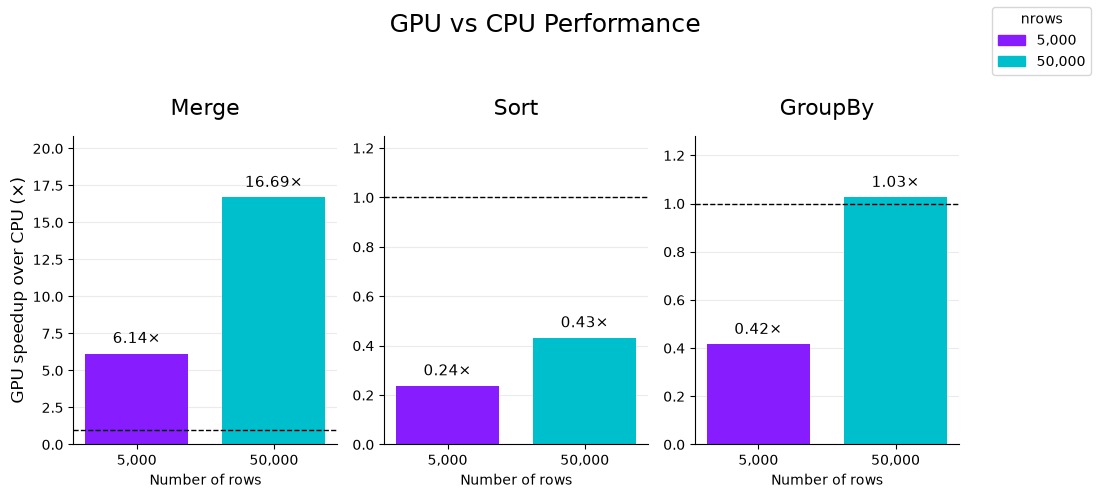

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

nrows = [5000, 50000]
colors = ["#871CFF", "#00BFCC"]

cpu = {
    "Merge":   np.array([97.7, 13000]),
    "Sort":    np.array([0.363, 1.39]),
    "GroupBy": np.array([0.519, 1.62]),
}
gpu = {
    "Merge":   np.array([15.9, 779]),
    "Sort":    np.array([1.53, 3.22]),
    "GroupBy": np.array([1.25, 1.58]),
}

fig, axes = plt.subplots(1, 3, figsize=(11, 5))
x = np.arange(len(nrows))

for ax, operation in zip(axes, cpu):
    speedup = cpu[operation] / gpu[operation]

    bars = ax.bar(x, speedup, color=colors, width=0.75)
    ax.bar_label(bars, labels=[f"{s:.2f}×" for s in speedup],
                 padding=5, fontsize=11)

    ax.axhline(1, color="black", linestyle="--", linewidth=1)
    ax.set_title(operation, fontsize=16, pad=15)
    ax.set_xticks(x, [f"{n:,}" for n in nrows])
    ax.set_xlabel("Number of rows")
    ax.set_ylim(0, max(1, speedup.max()) * 1.25)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("GPU speedup over CPU (×)", fontsize=12)

fig.legend(
    handles=[
        Patch(color=color, label=f"{n:,}")
        for color, n in zip(colors, nrows)
    ],
    title="nrows",
    loc="upper right",
)

fig.suptitle("GPU vs CPU Performance", fontsize=18)
fig.tight_layout(rect=[0, 0, 0.89, 0.92])
plt.show()

### Analysis

In [20]:
nrows = 500000

df1_data = {
'key': np.random.choice(['A', 'B', 'C', 'D'], size=nrows),
'value1': np.random.randint(1, 101, size=nrows)
}
df1 = pd.DataFrame(df1_data)


df2_data = {
'key': np.random.choice(['D', 'B', 'E', 'F'], size=nrows),
'value2': np.random.randint(1, 101, size=nrows)
}

df2 = pd.DataFrame(df2_data)

gpu_df1 = cf.from_pandas(df1)
gpu_df2 = cf.from_pandas(df2)

In [21]:
print("\nTesting group operation:")
print("\tOn CPU")
result = df1.groupby('key').size()
%timeit -n 5 result = df1.groupby('key').size()
print("\n\tOn GPU")
result = gpu_df1.groupby('key').size()
%timeit -n 5 result = gpu_df1.groupby('key').size(); cp.cuda.Device().synchronize()

print("\nTesting sort operation:")
print("\tOn CPU")
result = df1.sort_values(by='value1')
%timeit -n 5 result = df1.sort_values(by='value1')
print("\n\tOn GPU")
result = gpu_df1.sort_values(by='value1')
%timeit -n 5 result = gpu_df1.sort_values(by='value1'); cp.cuda.Device().synchronize()


Testing group operation:
	On CPU
15.4 ms ± 347 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)

	On GPU
2.67 ms ± 317 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)

Testing sort operation:
	On CPU
30.7 ms ± 196 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)

	On GPU
3.92 ms ± 25.9 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)
